In [1]:
print("Retail Sales Promotion Project - Setup Successful")

Retail Sales Promotion Project - Setup Successful


In [2]:
import pandas as pd
import numpy as np
import scipy
import statsmodels
import sklearn
import matplotlib
import seaborn as sns

print("All required libraries are working.")

All required libraries are working.


# Stage 2: Data Loading, Validation and Preparation

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

print("Project root:", PROJECT_ROOT)
print("Data folder:", DATA_DIR)

Project root: c:\Users\ritub\OneDrive\Attachments\Retail_Sales_Promotion_Project
Data folder: c:\Users\ritub\OneDrive\Attachments\Retail_Sales_Promotion_Project\data


In [5]:
print("Files in data folder:")
for file in DATA_DIR.iterdir():
    print(file.name)

Files in data folder:
sample_submission.csv
store.csv
test.csv
train.csv


In [6]:
train_path = DATA_DIR / "train.csv"
store_path = DATA_DIR / "store.csv"

train = pd.read_csv(train_path)
store = pd.read_csv(store_path)

print("Train dataset loaded.")
print("Store dataset loaded.")

Train dataset loaded.
Store dataset loaded.


C:\Users\ritub\AppData\Local\Temp\ipykernel_16408\3741101229.py:4: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv(train_path)


In [7]:
print("Train dataset shape:", train.shape)
print("Store dataset shape:", store.shape)

Train dataset shape: (1017209, 9)
Store dataset shape: (1115, 10)


In [8]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [9]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [10]:
print("TRAIN DATA TYPES")
print(train.dtypes)

print("\nSTORE DATA TYPES")
print(store.dtypes)

TRAIN DATA TYPES
Store             int64
DayOfWeek         int64
Date                str
Sales             int64
Customers         int64
Open              int64
Promo             int64
StateHoliday     object
SchoolHoliday     int64
dtype: object

STORE DATA TYPES
Store                          int64
StoreType                        str
Assortment                       str
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
PromoInterval                    str
dtype: object


In [11]:
print("Missing values in train:")
print(train.isnull().sum())

print("\nMissing values in store:")
print(store.isnull().sum())

Missing values in train:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Missing values in store:
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64


In [12]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in store:", store.duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in store: 0


In [13]:
duplicate_store_dates = train.duplicated(
    subset=["Store", "Date"]
).sum()

print("Duplicate Store-Date records:", duplicate_store_dates)

Duplicate Store-Date records: 0


In [14]:
print("Unique stores:", train["Store"].nunique())
print("Unique dates:", train["Date"].nunique())

print("\nDay of week values:")
print(sorted(train["DayOfWeek"].unique()))

print("\nPromo values:")
print(sorted(train["Promo"].unique()))

print("\nOpen values:")
print(sorted(train["Open"].unique()))

print("\nState holiday values:")
print(train["StateHoliday"].unique())

print("\nSchool holiday values:")
print(sorted(train["SchoolHoliday"].unique()))

Unique stores: 1115
Unique dates: 942

Day of week values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Promo values:
[np.int64(0), np.int64(1)]

Open values:
[np.int64(0), np.int64(1)]

State holiday values:
['0' 'a' 'b' 'c' 0]

School holiday values:
[np.int64(0), np.int64(1)]


In [15]:
print("Sales summary:")
print(train["Sales"].describe())

print("\nCustomers summary:")
print(train["Customers"].describe())

Sales summary:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Customers summary:
count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float64


In [16]:
print(train["Open"].value_counts())

Open
1    844392
0    172817
Name: count, dtype: int64


In [17]:
print(
    train.groupby("Open")["Sales"]
    .agg(["count", "mean", "median", "min", "max"])
)

       count         mean  median  min    max
Open                                         
0     172817     0.000000     0.0    0      0
1     844392  6955.514291  6369.0    0  41551


In [18]:
analysis_df = train[train["Open"] == 1].copy()

print("Original train rows:", len(train))
print("Open store-day rows:", len(analysis_df))

Original train rows: 1017209
Open store-day rows: 844392


In [19]:
analysis_df["Date"] = pd.to_datetime(analysis_df["Date"])

print(analysis_df["Date"].dtype)

datetime64[us]


In [20]:
analysis_df["Year"] = analysis_df["Date"].dt.year
analysis_df["Month"] = analysis_df["Date"].dt.month
analysis_df["MonthName"] = analysis_df["Date"].dt.month_name()

print(
    analysis_df[
        ["Date", "Year", "Month", "MonthName"]
    ].head()
)

        Date  Year  Month MonthName
0 2015-07-31  2015      7      July
1 2015-07-31  2015      7      July
2 2015-07-31  2015      7      July
3 2015-07-31  2015      7      July
4 2015-07-31  2015      7      July


In [21]:
categorical_columns = [
    "StoreType",
    "Assortment",
    "StateHoliday"
]

for col in categorical_columns:
    if col in analysis_df.columns:
        analysis_df[col] = analysis_df[col].astype("category")

In [22]:
analysis_df = analysis_df.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", analysis_df.shape)

Merged dataset shape: (844392, 21)


In [23]:
analysis_df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,MonthName,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,2015,7,July,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,2015,7,July,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,2015,7,July,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015,7,July,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,2015,7,July,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [24]:
print("Missing StoreType values:", analysis_df["StoreType"].isna().sum())
print("Missing Assortment values:", analysis_df["Assortment"].isna().sum())
print(
    "Missing CompetitionDistance values:",
    analysis_df["CompetitionDistance"].isna().sum()
)

Missing StoreType values: 0
Missing Assortment values: 0
Missing CompetitionDistance values: 2186


In [25]:
categorical_columns = [
    "StoreType",
    "Assortment",
    "StateHoliday"
]

for col in categorical_columns:
    analysis_df[col] = analysis_df[col].astype("category")

In [26]:
print("Final analysis dataset shape:", analysis_df.shape)

print("\nData types:")
print(analysis_df.dtypes)

print("\nMissing values:")
print(analysis_df.isnull().sum())

Final analysis dataset shape: (844392, 21)

Data types:
Store                                 int64
DayOfWeek                             int64
Date                         datetime64[us]
Sales                                 int64
Customers                             int64
Open                                  int64
Promo                                 int64
StateHoliday                       category
SchoolHoliday                         int64
Year                                  int32
Month                                 int32
MonthName                               str
StoreType                          category
Assortment                         category
CompetitionDistance                 float64
CompetitionOpenSinceMonth           float64
CompetitionOpenSinceYear            float64
Promo2                                int64
Promo2SinceWeek                     float64
Promo2SinceYear                     float64
PromoInterval                           str
dtype: object

Missi

In [27]:
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

cleaned_path = OUTPUT_DIR / "analysis_dataset.csv"

analysis_df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved to:")
print(cleaned_path)

Cleaned dataset saved to:
c:\Users\ritub\OneDrive\Attachments\Retail_Sales_Promotion_Project\outputs\analysis_dataset.csv


# Stage 3: Exploratory Data Analysis (M1)

In [28]:
print("Analysis dataset shape:", analysis_df.shape)

print("\nColumns:")
print(analysis_df.columns.tolist())

Analysis dataset shape: (844392, 21)

Columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'MonthName', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


In [29]:
analysis_df[["Sales", "Customers", "CompetitionDistance"]].describe()

,Sales,Customers,CompetitionDistance
count,844392.000000,844392.000000,842206.000000
mean,6955.514291,762.728395,5457.979627
std,3104.214680,401.227674,7809.437311
min,0.000000,0.000000,20.000000
25%,4859.000000,519.000000,710.000000
50%,6369.000000,676.000000,2320.000000
75%,8360.000000,893.000000,6890.000000
max,41551.000000,7388.000000,75860.000000


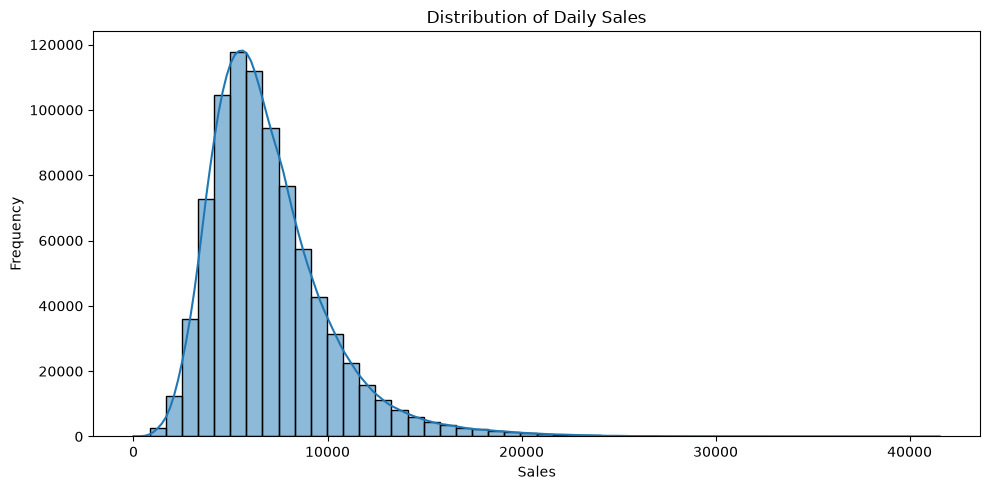

In [30]:
plt.figure(figsize=(10, 5))

sns.histplot(
    analysis_df["Sales"],
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

In [31]:
sales_skewness = analysis_df["Sales"].skew()

print("Sales skewness:", sales_skewness)

Sales skewness: 1.5939220392699807


In [32]:
day_summary = (
    analysis_df
    .groupby("DayOfWeek", observed=True)["Sales"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

day_summary

,DayOfWeek,count,mean,median,std
0,1,137560,8216.073074,7539.0,3691.768876
1,2,143961,7088.113656,6502.0,3066.237110
2,3,141936,6728.122978,6210.0,2781.775174
3,4,134644,6767.310159,6246.0,2764.548119
4,5,138640,7072.677012,6580.0,2764.915744
5,6,144058,5874.840238,5425.0,2852.730426
6,7,3593,8224.723908,6876.0,6235.152960


In [33]:
day_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

day_summary["Day"] = day_summary["DayOfWeek"].map(day_names)

day_summary

,DayOfWeek,count,mean,median,std,Day
0,1,137560,8216.073074,7539.0,3691.768876,Monday
1,2,143961,7088.113656,6502.0,3066.237110,Tuesday
2,3,141936,6728.122978,6210.0,2781.775174,Wednesday
3,4,134644,6767.310159,6246.0,2764.548119,Thursday
4,5,138640,7072.677012,6580.0,2764.915744,Friday
5,6,144058,5874.840238,5425.0,2852.730426,Saturday
6,7,3593,8224.723908,6876.0,6235.152960,Sunday


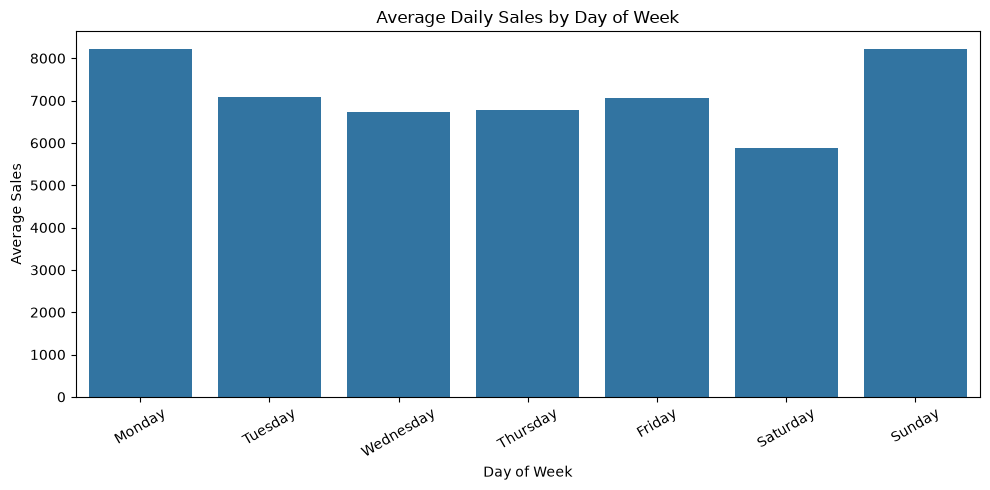

In [34]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=day_summary,
    x="Day",
    y="mean"
)

plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "sales_by_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

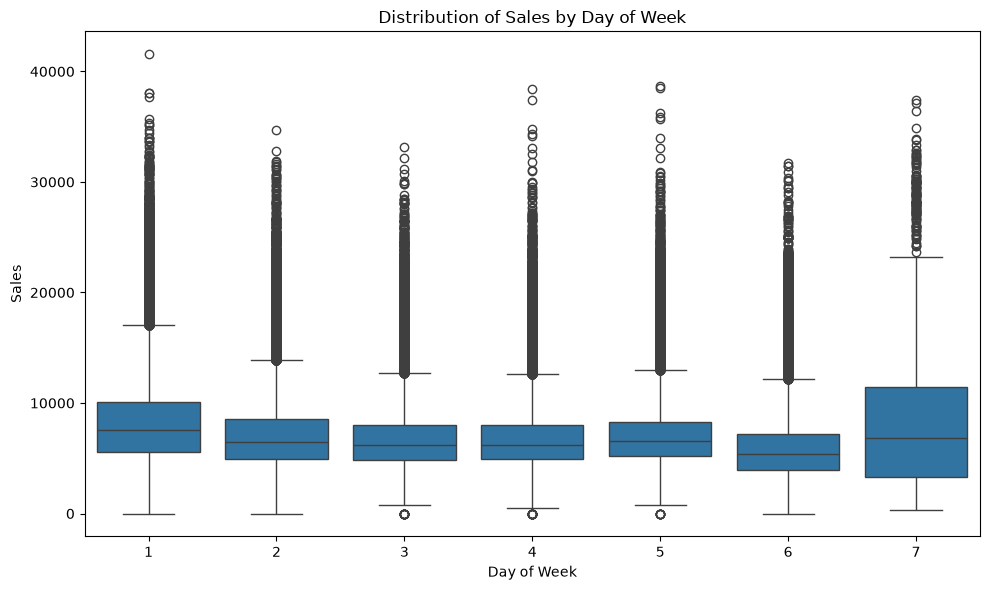

In [35]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=analysis_df,
    x="DayOfWeek",
    y="Sales"
)

plt.title("Distribution of Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Sales")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "sales_distribution_by_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
month_summary = (
    analysis_df
    .groupby("Month", observed=True)["Sales"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

month_summary

,Month,count,mean,median,std
0,1,86343,6563.690444,6062.0,2849.588618
1,2,80243,6589.165535,6078.0,2870.958982
2,3,85980,6976.412026,6385.0,3123.919916
3,4,81731,7046.228420,6431.0,3138.850850
4,5,80103,7106.453154,6592.0,3008.182746
5,6,82576,7000.978190,6365.0,3145.066576
6,7,85587,6952.682125,6407.0,3004.087868
7,8,54413,6648.984654,6124.0,2901.801310
8,9,52330,6546.343035,5999.0,2890.460475
9,10,53292,6602.843354,6105.0,2814.725466


In [37]:
month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

month_summary["MonthName"] = month_summary["Month"].map(month_names)

month_summary

,Month,count,mean,median,std,MonthName
0,1,86343,6563.690444,6062.0,2849.588618,January
1,2,80243,6589.165535,6078.0,2870.958982,February
2,3,85980,6976.412026,6385.0,3123.919916,March
3,4,81731,7046.228420,6431.0,3138.850850,April
4,5,80103,7106.453154,6592.0,3008.182746,May
5,6,82576,7000.978190,6365.0,3145.066576,June
6,7,85587,6952.682125,6407.0,3004.087868,July
7,8,54413,6648.984654,6124.0,2901.801310,August
8,9,52330,6546.343035,5999.0,2890.460475,September
9,10,53292,6602.843354,6105.0,2814.725466,October


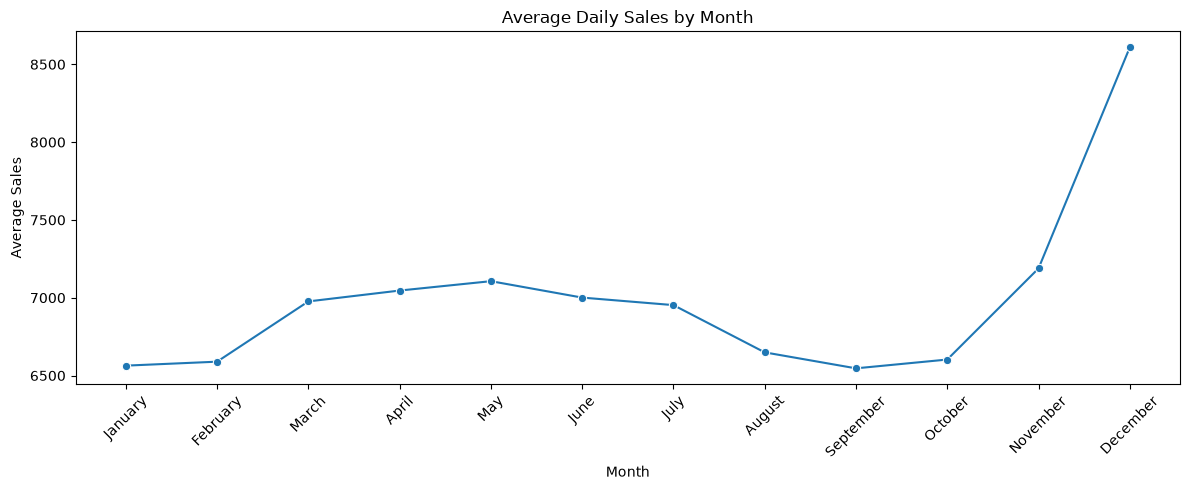

In [38]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=month_summary,
    x="MonthName",
    y="mean",
    marker="o"
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "sales_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
year_month_summary = (
    analysis_df
    .groupby(["Year", "Month"], observed=True)["Sales"]
    .mean()
    .reset_index()
)

year_month_summary["YearMonth"] = (
    year_month_summary["Year"].astype(str)
    + "-"
    + year_month_summary["Month"].astype(str).str.zfill(2)
)

year_month_summary.head()

,Year,Month,Sales,YearMonth
0,2013,1,6239.641380,2013-01
1,2013,2,6428.597796,2013-02
2,2013,3,7212.834110,2013-03
3,2013,4,6579.319656,2013-04
4,2013,5,7076.217960,2013-05


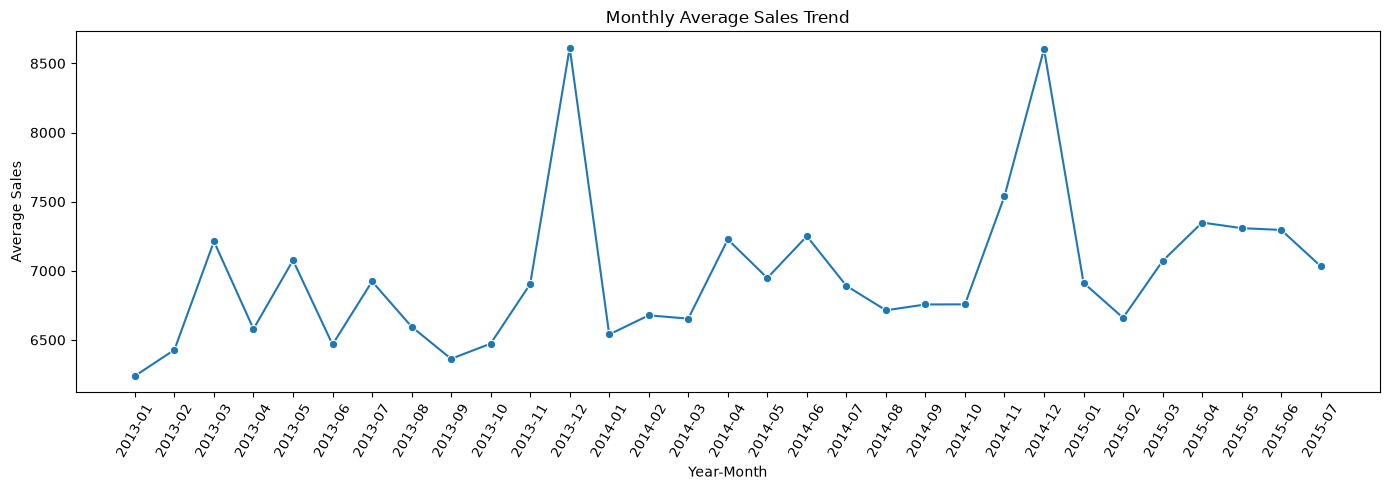

In [40]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=year_month_summary,
    x="YearMonth",
    y="Sales",
    marker="o"
)

plt.title("Monthly Average Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Average Sales")
plt.xticks(rotation=60)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
promo_summary = (
    analysis_df
    .groupby("Promo", observed=True)["Sales"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

promo_summary

,Promo,count,mean,median,std
0,0,467496,5929.407603,5459.0,2629.648385
1,1,376896,8228.281239,7649.0,3175.759157


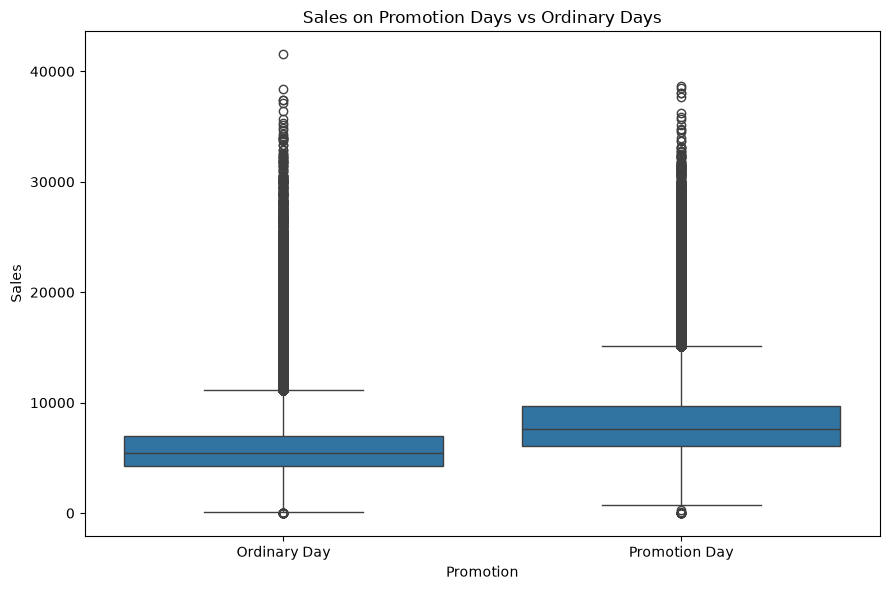

In [42]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=analysis_df,
    x="Promo",
    y="Sales"
)

plt.title("Sales on Promotion Days vs Ordinary Days")
plt.xlabel("Promotion")
plt.ylabel("Sales")

plt.xticks(
    [0, 1],
    ["Ordinary Day", "Promotion Day"]
)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "promotion_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
ordinary_mean = analysis_df.loc[
    analysis_df["Promo"] == 0, "Sales"
].mean()

promotion_mean = analysis_df.loc[
    analysis_df["Promo"] == 1, "Sales"
].mean()

absolute_uplift = promotion_mean - ordinary_mean

percentage_uplift = (
    absolute_uplift / ordinary_mean
) * 100

print("Mean sales on ordinary days:", ordinary_mean)
print("Mean sales on promotion days:", promotion_mean)
print("Absolute uplift:", absolute_uplift)
print("Percentage uplift:", percentage_uplift, "%")

Mean sales on ordinary days: 5929.407603487516
Mean sales on promotion days: 8228.281239386994
Absolute uplift: 2298.8736358994774
Percentage uplift: 38.77071352874008 %


In [44]:
store_type_frequency = (
    analysis_df["StoreType"]
    .value_counts()
    .sort_index()
)

store_type_frequency

StoreType
a    457077
b     15563
c    112978
d    258774
Name: count, dtype: int64

In [45]:
store_type_percentage = (
    analysis_df["StoreType"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

store_type_table = pd.DataFrame({
    "Frequency": store_type_frequency,
    "Percentage": store_type_percentage.round(2)
})

store_type_table

,Frequency,Percentage
StoreType,,
a,457077,54.13
b,15563,1.84
c,112978,13.38
d,258774,30.65


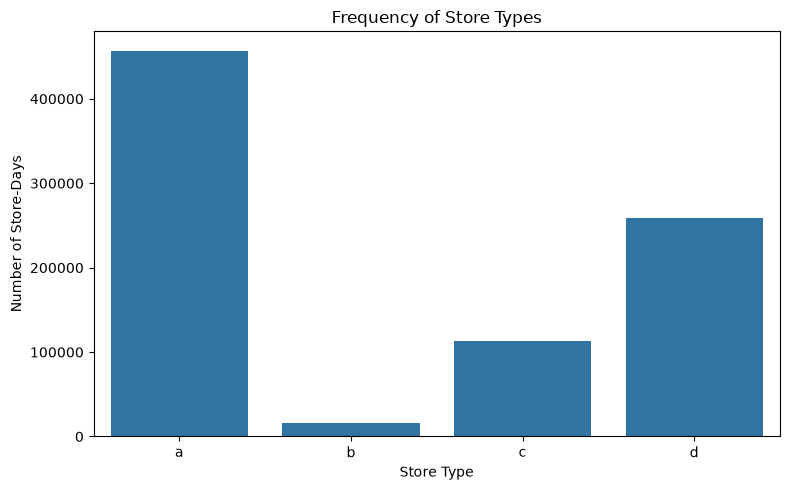

In [46]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=analysis_df,
    x="StoreType"
)

plt.title("Frequency of Store Types")
plt.xlabel("Store Type")
plt.ylabel("Number of Store-Days")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "store_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
store_promo_summary = (
    analysis_df
    .groupby(["StoreType", "Promo"], observed=True)["Sales"]
    .mean()
    .reset_index()
)

store_promo_summary

,StoreType,Promo,Sales
0,a,0,5808.500091
1,a,1,8304.102317
2,b,0,9566.861686
3,b,1,11307.994108
4,c,0,6028.063255
5,c,1,8041.995526
6,d,0,5855.268289
7,d,1,8017.828656


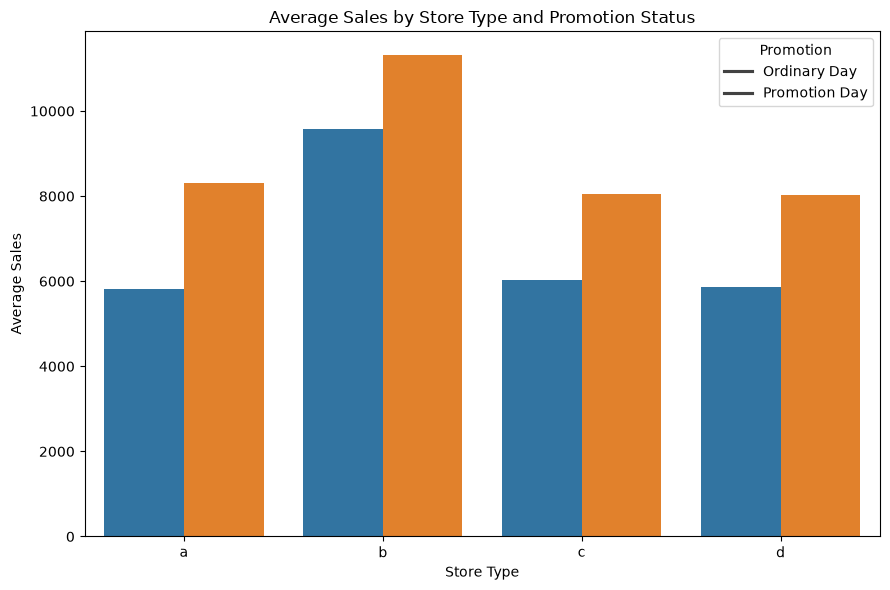

In [48]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=store_promo_summary,
    x="StoreType",
    y="Sales",
    hue="Promo"
)

plt.title("Average Sales by Store Type and Promotion Status")
plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.legend(
    title="Promotion",
    labels=["Ordinary Day", "Promotion Day"]
)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "store_type_promotion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
day_promo_summary = (
    analysis_df
    .groupby(["DayOfWeek", "Promo"], observed=True)["Sales"]
    .mean()
    .reset_index()
)

day_promo_summary

,DayOfWeek,Promo,Sales
0,1,0,6222.521495
1,1,1,9772.784369
2,2,0,5716.241087
3,2,1,8277.201522
4,3,0,5617.044778
5,3,1,7685.077816
6,4,0,5749.837412
7,4,1,7598.070761
8,5,0,6344.030127
9,5,1,7744.066219


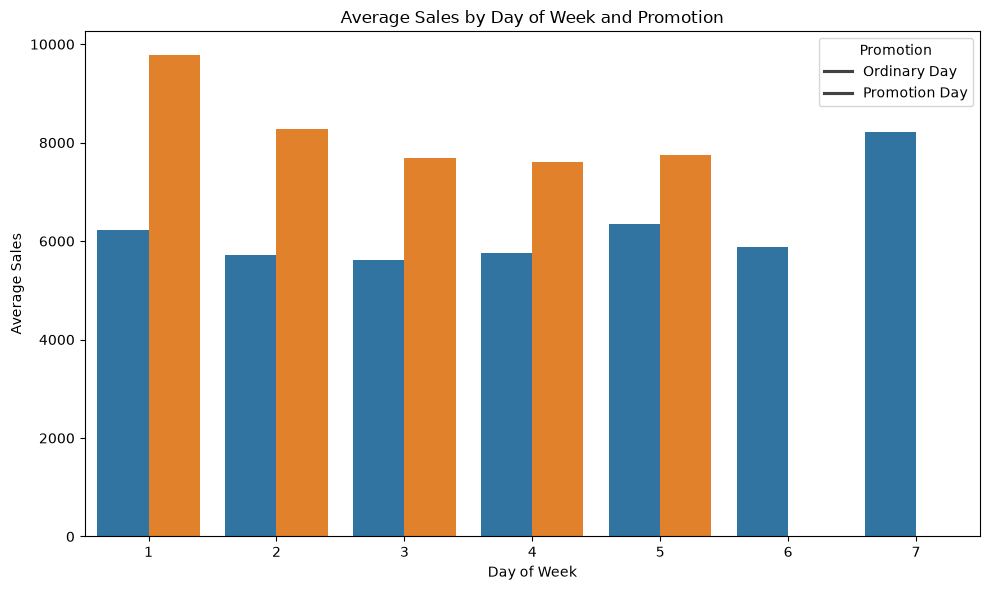

In [50]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=day_promo_summary,
    x="DayOfWeek",
    y="Sales",
    hue="Promo"
)

plt.title("Average Sales by Day of Week and Promotion")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")

plt.legend(
    title="Promotion",
    labels=["Ordinary Day", "Promotion Day"]
)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "day_promotion_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
day_summary.to_csv(
    OUTPUT_DIR / "sales_by_day_summary.csv",
    index=False
)

month_summary.to_csv(
    OUTPUT_DIR / "sales_by_month_summary.csv",
    index=False
)

promo_summary.to_csv(
    OUTPUT_DIR / "promotion_sales_summary.csv",
    index=False
)

store_type_table.to_csv(
    OUTPUT_DIR / "store_type_frequency.csv"
)

store_promo_summary.to_csv(
    OUTPUT_DIR / "store_type_promotion_summary.csv",
    index=False
)

print("M1 summary tables saved successfully.")

M1 summary tables saved successfully.


# Stage 4: Sampling and Bootstrap Analysis (M2)

### Choice of Resampling Unit

The observational unit in this analysis is a store-day, representing the sales
record for one store on one specific day. The bootstrap procedure therefore
resamples store-day observations rather than individual customers.

This choice is appropriate because the Rossmann dataset records sales at the
store-day level. Resampling at this level preserves the structure of the
available observations and matches the unit at which promotion status and
daily sales are measured.

In [52]:
promo_counts = (
    analysis_df["Promo"]
    .value_counts()
    .sort_index()
)

print("Number of ordinary store-days:", promo_counts.get(0, 0))
print("Number of promotion store-days:", promo_counts.get(1, 0))

Number of ordinary store-days: 467496
Number of promotion store-days: 376896


In [53]:
ordinary_sales = analysis_df.loc[
    analysis_df["Promo"] == 0, "Sales"
].to_numpy()

promotion_sales = analysis_df.loc[
    analysis_df["Promo"] == 1, "Sales"
].to_numpy()

observed_ordinary_mean = ordinary_sales.mean()
observed_promotion_mean = promotion_sales.mean()

observed_uplift = (
    observed_promotion_mean - observed_ordinary_mean
)

print("Ordinary-day mean:", observed_ordinary_mean)
print("Promotion-day mean:", observed_promotion_mean)
print("Observed mean uplift:", observed_uplift)

Ordinary-day mean: 5929.407603487516
Promotion-day mean: 8228.281239386994
Observed mean uplift: 2298.8736358994774


In [54]:
observed_percentage_uplift = (
    observed_uplift / observed_ordinary_mean
) * 100

print(
    f"Observed percentage uplift: "
    f"{observed_percentage_uplift:.2f}%"
)

Observed percentage uplift: 38.77%


In [55]:
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


In [56]:
n_bootstrap = 10_000

bootstrap_uplifts = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    ordinary_sample = rng.choice(
        ordinary_sales,
        size=len(ordinary_sales),
        replace=True
    )

    promotion_sample = rng.choice(
        promotion_sales,
        size=len(promotion_sales),
        replace=True
    )

    ordinary_mean = ordinary_sample.mean()
    promotion_mean = promotion_sample.mean()

    bootstrap_uplifts[i] = (
        promotion_mean - ordinary_mean
    )

print("Bootstrap repetitions:", n_bootstrap)
print("Bootstrap completed.")

Bootstrap repetitions: 10000
Bootstrap completed.


In [57]:
print("Bootstrap mean uplift:", bootstrap_uplifts.mean())
print("Bootstrap standard deviation:", bootstrap_uplifts.std())
print("Minimum bootstrap uplift:", bootstrap_uplifts.min())
print("Maximum bootstrap uplift:", bootstrap_uplifts.max())

Bootstrap mean uplift: 2298.9485426982774
Bootstrap standard deviation: 6.454387807251916
Minimum bootstrap uplift: 2270.869116095275
Maximum bootstrap uplift: 2325.537871056239


In [58]:
ci_lower = np.percentile(
    bootstrap_uplifts,
    2.5
)

ci_upper = np.percentile(
    bootstrap_uplifts,
    97.5
)

print(f"95% Bootstrap CI: ({ci_lower:.2f}, {ci_upper:.2f})")

95% Bootstrap CI: (2286.64, 2311.56)


In [59]:
bootstrap_se = bootstrap_uplifts.std(ddof=1)

print(f"Bootstrap standard error: {bootstrap_se:.2f}")

Bootstrap standard error: 6.45


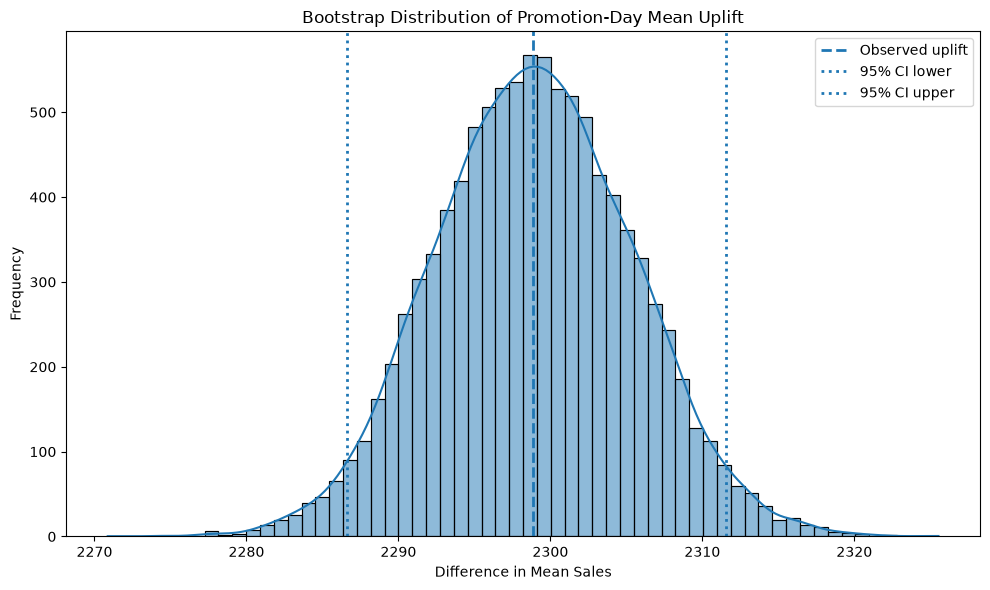

In [60]:
plt.figure(figsize=(10, 6))

sns.histplot(
    bootstrap_uplifts,
    bins=60,
    kde=True
)

plt.axvline(
    observed_uplift,
    linestyle="--",
    linewidth=2,
    label="Observed uplift"
)

plt.axvline(
    ci_lower,
    linestyle=":",
    linewidth=2,
    label="95% CI lower"
)

plt.axvline(
    ci_upper,
    linestyle=":",
    linewidth=2,
    label="95% CI upper"
)

plt.title("Bootstrap Distribution of Promotion-Day Mean Uplift")
plt.xlabel("Difference in Mean Sales")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "bootstrap_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
bootstrap_percentage_uplifts = (
    bootstrap_uplifts / observed_ordinary_mean
) * 100

percentage_ci_lower = np.percentile(
    bootstrap_percentage_uplifts,
    2.5
)

percentage_ci_upper = np.percentile(
    bootstrap_percentage_uplifts,
    97.5
)

print(
    f"95% CI for percentage uplift: "
    f"({percentage_ci_lower:.2f}%, "
    f"{percentage_ci_upper:.2f}%)"
)

95% CI for percentage uplift: (38.56%, 38.98%)


In [62]:
bootstrap_results = pd.DataFrame({
    "Statistic": [
        "Ordinary-day mean sales",
        "Promotion-day mean sales",
        "Observed mean uplift",
        "Observed percentage uplift",
        "Bootstrap standard error",
        "95% CI lower",
        "95% CI upper",
        "Percentage uplift CI lower",
        "Percentage uplift CI upper"
    ],
    "Value": [
        observed_ordinary_mean,
        observed_promotion_mean,
        observed_uplift,
        observed_percentage_uplift,
        bootstrap_se,
        ci_lower,
        ci_upper,
        percentage_ci_lower,
        percentage_ci_upper
    ]
})

bootstrap_results

,Statistic,Value
0,Ordinary-day mean sales,5929.407603
1,Promotion-day mean sales,8228.281239
2,Observed mean uplift,2298.873636
3,Observed percentage uplift,38.770714
4,Bootstrap standard error,6.454711
5,95% CI lower,2286.638298
6,95% CI upper,2311.561173
7,Percentage uplift CI lower,38.564363
8,Percentage uplift CI upper,38.984690


In [63]:
bootstrap_results.to_csv(
    OUTPUT_DIR / "bootstrap_results.csv",
    index=False
)

print("Bootstrap results saved successfully.")

Bootstrap results saved successfully.


In [64]:
ordinary_log_sales = np.log1p(ordinary_sales)
promotion_log_sales = np.log1p(promotion_sales)

print("Log transformation completed.")

Log transformation completed.


In [65]:
log_bootstrap_uplifts = np.empty(n_bootstrap)

rng_log = np.random.default_rng(RANDOM_SEED)

for i in range(n_bootstrap):
    ordinary_sample = rng_log.choice(
        ordinary_log_sales,
        size=len(ordinary_log_sales),
        replace=True
    )

    promotion_sample = rng_log.choice(
        promotion_log_sales,
        size=len(promotion_log_sales),
        replace=True
    )

    log_bootstrap_uplifts[i] = (
        promotion_sample.mean()
        - ordinary_sample.mean()
    )

print("Log-scale bootstrap completed.")

Log-scale bootstrap completed.


In [66]:
log_observed_uplift = (
    promotion_log_sales.mean()
    - ordinary_log_sales.mean()
)

log_ci_lower = np.percentile(
    log_bootstrap_uplifts,
    2.5
)

log_ci_upper = np.percentile(
    log_bootstrap_uplifts,
    97.5
)

print(
    f"Observed log-scale difference: "
    f"{log_observed_uplift:.4f}"
)

print(
    f"95% CI on log scale: "
    f"({log_ci_lower:.4f}, {log_ci_upper:.4f})"
)

Observed log-scale difference: 0.3463
95% CI on log scale: (0.3446, 0.3479)


### Bootstrap Interpretation

The bootstrap procedure estimates the sampling uncertainty associated with the
difference in mean sales between promotion and ordinary store-days.

A 95% bootstrap confidence interval provides a range of values compatible with
the observed data under repeated resampling of store-day observations.

The bootstrap result describes the observed association between promotion status
and sales. It should not by itself be interpreted as proof of a causal promotion
effect because other factors, such as day of week, store type and holidays, may
also differ between promotion and non-promotion observations.

# Stage 5: Significance Testing (M3)

### Hypotheses

**Null hypothesis (H₀):**  
The mean sales on promotion store-days is equal to the mean sales on
ordinary store-days.

**Alternative hypothesis (H₁):**  
The mean sales on promotion store-days is different from the mean sales on
ordinary store-days.

A two-sided test is used because the objective is to determine whether there is
a statistically significant difference rather than assuming the direction of
the difference in advance.

In [67]:
ordinary_sales = analysis_df.loc[
    analysis_df["Promo"] == 0, "Sales"
].dropna()

promotion_sales = analysis_df.loc[
    analysis_df["Promo"] == 1, "Sales"
].dropna()

print("Ordinary store-days:", len(ordinary_sales))
print("Promotion store-days:", len(promotion_sales))

Ordinary store-days: 467496
Promotion store-days: 376896


In [68]:
ordinary_stats = ordinary_sales.agg(
    ["count", "mean", "median", "std"]
)

promotion_stats = promotion_sales.agg(
    ["count", "mean", "median", "std"]
)

print("Ordinary-day statistics:")
print(ordinary_stats)

print("\nPromotion-day statistics:")
print(promotion_stats)

Ordinary-day statistics:
count     467496.000000
mean        5929.407603
median      5459.000000
std         2629.648385
Name: Sales, dtype: float64

Promotion-day statistics:
count     376896.000000
mean        8228.281239
median      7649.000000
std         3175.759157
Name: Sales, dtype: float64


In [69]:
from scipy import stats

t_statistic, p_value = stats.ttest_ind(
    promotion_sales,
    ordinary_sales,
    equal_var=False
)

print("Welch's t-statistic:", t_statistic)
print("p-value:", p_value)

Welch's t-statistic: 356.6357238880086
p-value: 0.0


In [70]:
mean_difference = (
    promotion_sales.mean()
    - ordinary_sales.mean()
)

print("Mean difference:", mean_difference)

Mean difference: 2298.8736358994774


In [71]:
n_promo = len(promotion_sales)
n_ordinary = len(ordinary_sales)

mean_promo = promotion_sales.mean()
mean_ordinary = ordinary_sales.mean()

var_promo = promotion_sales.var(ddof=1)
var_ordinary = ordinary_sales.var(ddof=1)

standard_error_difference = np.sqrt(
    (var_promo / n_promo)
    + (var_ordinary / n_ordinary)
)

degrees_of_freedom = (
    (
        (var_promo / n_promo)
        + (var_ordinary / n_ordinary)
    ) ** 2
    /
    (
        ((var_promo / n_promo) ** 2 / (n_promo - 1))
        +
        ((var_ordinary / n_ordinary) ** 2 / (n_ordinary - 1))
    )
)

critical_value = stats.t.ppf(
    0.975,
    degrees_of_freedom
)

ci_ttest_lower = (
    mean_difference
    - critical_value * standard_error_difference
)

ci_ttest_upper = (
    mean_difference
    + critical_value * standard_error_difference
)

print("Degrees of freedom:", degrees_of_freedom)
print("Standard error:", standard_error_difference)
print(
    f"95% CI for mean difference: "
    f"({ci_ttest_lower:.2f}, {ci_ttest_upper:.2f})"
)

Degrees of freedom: 729119.0299799585
Standard error: 6.445999326251942
95% CI for mean difference: (2286.24, 2311.51)


In [72]:
pooled_std = np.sqrt(
    (
        (n_promo - 1) * var_promo
        +
        (n_ordinary - 1) * var_ordinary
    )
    /
    (
        n_promo + n_ordinary - 2
    )
)

cohens_d = mean_difference / pooled_std

print("Cohen's d:", cohens_d)

Cohen's d: 0.7965047406136166


In [73]:
percentage_difference = (
    mean_difference / mean_ordinary
) * 100

print(
    f"Percentage difference in mean sales: "
    f"{percentage_difference:.2f}%"
)

Percentage difference in mean sales: 38.77%


In [74]:
alpha = 0.05

if p_value < alpha:
    significance_result = "Statistically significant"
else:
    significance_result = "Not statistically significant"

print("Significance level:", alpha)
print("Result:", significance_result)

Significance level: 0.05
Result: Statistically significant


In [75]:
ttest_results = pd.DataFrame({
    "Statistic": [
        "Ordinary-day mean",
        "Promotion-day mean",
        "Mean difference",
        "Percentage difference",
        "Welch t-statistic",
        "Welch degrees of freedom",
        "p-value",
        "95% CI lower",
        "95% CI upper",
        "Cohen's d",
        "Significance level"
    ],
    "Value": [
        mean_ordinary,
        mean_promo,
        mean_difference,
        percentage_difference,
        t_statistic,
        degrees_of_freedom,
        p_value,
        ci_ttest_lower,
        ci_ttest_upper,
        cohens_d,
        alpha
    ]
})

ttest_results

,Statistic,Value
0,Ordinary-day mean,5929.407603
1,Promotion-day mean,8228.281239
2,Mean difference,2298.873636
3,Percentage difference,38.770714
4,Welch t-statistic,356.635724
5,Welch degrees of freedom,729119.029980
6,p-value,0.000000
7,95% CI lower,2286.239688
8,95% CI upper,2311.507583
9,Cohen's d,0.796505


In [76]:
ttest_results.to_csv(
    OUTPUT_DIR / "ttest_results.csv",
    index=False
)

print("T-test results saved successfully.")

T-test results saved successfully.


In [77]:
comparison_results = pd.DataFrame({
    "Method": [
        "Bootstrap",
        "Welch t-test"
    ],
    "Estimate": [
        observed_uplift,
        mean_difference
    ],
    "CI Lower": [
        ci_lower,
        ci_ttest_lower
    ],
    "CI Upper": [
        ci_upper,
        ci_ttest_upper
    ]
})

comparison_results

,Method,Estimate,CI Lower,CI Upper
0,Bootstrap,2298.873636,2286.638298,2311.561173
1,Welch t-test,2298.873636,2286.239688,2311.507583


### Comparison of Bootstrap and t-test Results

The bootstrap confidence interval and the Welch t-test confidence interval are
compared to assess whether the estimated promotion-day difference is reasonably
stable under two different statistical approaches.

The bootstrap approach does not rely on the same normal-theory approximation
used by the t-test and instead estimates the sampling distribution through
resampling. Agreement between the two approaches provides a useful robustness
check for the estimated difference.

### Statistical Significance vs Commercial Significance

Statistical significance evaluates whether the observed difference provides
evidence against the null hypothesis under the chosen statistical model.

Commercial significance is different. It considers whether the magnitude of the
observed sales difference is large enough to have meaningful business value
after considering factors such as promotion cost, profit margin, inventory,
customer demand and operational constraints.

Therefore, a statistically significant difference should not automatically be
interpreted as a commercially successful promotion.

In [78]:
print("=" * 60)
print("SIGNIFICANCE TESTING SUMMARY")
print("=" * 60)

print(f"Ordinary-day mean sales : {mean_ordinary:.2f}")
print(f"Promotion-day mean sales: {mean_promo:.2f}")
print(f"Mean difference         : {mean_difference:.2f}")
print(f"Percentage difference   : {percentage_difference:.2f}%")
print(f"Welch t-statistic       : {t_statistic:.4f}")
print(f"p-value                 : {p_value:.6g}")
print(
    f"95% CI                  : "
    f"({ci_ttest_lower:.2f}, {ci_ttest_upper:.2f})"
)
print(f"Cohen's d               : {cohens_d:.4f}")
print(f"Statistical result      : {significance_result}")

SIGNIFICANCE TESTING SUMMARY
Ordinary-day mean sales : 5929.41
Promotion-day mean sales: 8228.28
Mean difference         : 2298.87
Percentage difference   : 38.77%
Welch t-statistic       : 356.6357
p-value                 : 0
95% CI                  : (2286.24, 2311.51)
Cohen's d               : 0.7965
Statistical result      : Statistically significant


# Stage 6: Regression and Diagnostics (M4)

In [79]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.outliers_influence import OLSInfluence

print("Regression libraries imported successfully.")

Regression libraries imported successfully.


In [80]:
required_variables = [
    "Sales",
    "Promo",
    "DayOfWeek",
    "StoreType",
    "StateHoliday",
    "SchoolHoliday"
]

missing_variables = [
    col for col in required_variables
    if col not in analysis_df.columns
]

print("Missing required variables:", missing_variables)

Missing required variables: []


In [81]:
regression_df = analysis_df.copy()

regression_df["DayOfWeek"] = regression_df["DayOfWeek"].astype("category")
regression_df["StoreType"] = regression_df["StoreType"].astype("category")
regression_df["StateHoliday"] = regression_df["StateHoliday"].astype("category")

print(regression_df[
    ["Sales", "Promo", "DayOfWeek", "StoreType", "StateHoliday"]
].dtypes)

Sales              int64
Promo              int64
DayOfWeek       category
StoreType       category
StateHoliday    category
dtype: object


In [82]:
print("Regression dataset shape:", regression_df.shape)

print("\nMissing values:")
print(
    regression_df[
        required_variables
    ].isnull().sum()
)

Regression dataset shape: (844392, 21)

Missing values:
Sales            0
Promo            0
DayOfWeek        0
StoreType        0
StateHoliday     0
SchoolHoliday    0
dtype: int64


In [83]:
model_main = smf.ols(
    formula="""
        Sales ~ Promo
        + C(DayOfWeek)
        + C(StoreType)
    """,
    data=regression_df
).fit()

print(model_main.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.182
Model:                            OLS   Adj. R-squared:                  0.182
Method:                 Least Squares   F-statistic:                 1.878e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:16:10   Log-Likelihood:            -7.9027e+06
No. Observations:              844392   AIC:                         1.581e+07
Df Residuals:                  844381   BIC:                         1.581e+07
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          6908.0493      8.92

In [84]:
print("Day of week categories:")
print(regression_df["DayOfWeek"].cat.categories)

print("\nStore type categories:")
print(regression_df["StoreType"].cat.categories)

Day of week categories:
Index([1, 2, 3, 4, 5, 6, 7], dtype='int64')

Store type categories:
Index(['a', 'b', 'c', 'd'], dtype='str')


In [85]:
main_coefficients = pd.DataFrame({
    "Coefficient": model_main.params,
    "Std_Error": model_main.bse,
    "t_value": model_main.tvalues,
    "p_value": model_main.pvalues,
    "CI_Lower": model_main.conf_int()[0],
    "CI_Upper": model_main.conf_int()[1]
})

main_coefficients

,Coefficient,Std_Error,t_value,p_value,CI_Lower,CI_Upper
Intercept,6908.049312,8.920840,774.372034,0.000000e+00,6890.564761,6925.533862
C(DayOfWeek)[T.2],-1066.737278,10.587559,-100.753843,0.000000e+00,-1087.488543,-1045.986014
C(DayOfWeek)[T.3],-1431.083506,10.624214,-134.700179,0.000000e+00,-1451.906612,-1410.260400
C(DayOfWeek)[T.4],-1425.277827,10.763857,-132.413306,0.000000e+00,-1446.374628,-1404.181025
C(DayOfWeek)[T.5],-1049.430311,10.688513,-98.183000,0.000000e+00,-1070.379442,-1028.481179
C(DayOfWeek)[T.6],-1055.041029,11.243082,-93.839131,0.000000e+00,-1077.077096,-1033.004961
C(DayOfWeek)[T.7],-788.135212,49.692943,-15.860103,1.219777e-56,-885.531730,-690.738695
C(StoreType)[T.b],3425.477594,23.894733,143.357014,0.000000e+00,3378.644710,3472.310477
C(StoreType)[T.c],4.445131,9.329346,0.476468,6.337414e-01,-13.840077,22.730339
C(StoreType)[T.d],-102.081973,6.907576,-14.778262,2.052232e-49,-115.620593,-88.543353


In [86]:
main_coefficients.to_csv(
    OUTPUT_DIR / "regression_main_effects.csv"
)

print("Main-effects regression coefficients saved.")

Main-effects regression coefficients saved.


In [87]:
model_interaction = smf.ols(
    formula="""
        Sales ~ Promo
        + C(DayOfWeek)
        + C(StoreType)
        + Promo:C(StoreType)
    """,
    data=regression_df
).fit()

print(model_interaction.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.183
Model:                            OLS   Adj. R-squared:                  0.183
Method:                 Least Squares   F-statistic:                 1.455e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:16:13   Log-Likelihood:            -7.9022e+06
No. Observations:              844392   AIC:                         1.580e+07
Df Residuals:                  844378   BIC:                         1.580e+07
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                6

In [88]:
interaction_coefficients = pd.DataFrame({
    "Coefficient": model_interaction.params,
    "Std_Error": model_interaction.bse,
    "t_value": model_interaction.tvalues,
    "p_value": model_interaction.pvalues,
    "CI_Lower": model_interaction.conf_int()[0],
    "CI_Upper": model_interaction.conf_int()[1]
})

interaction_coefficients

,Coefficient,Std_Error,t_value,p_value,CI_Lower,CI_Upper
Intercept,6828.111456,9.265030,736.976758,0.000000e+00,6809.952306,6846.270606
C(DayOfWeek)[T.2],-1066.658548,10.580622,-100.812459,0.000000e+00,-1087.396216,-1045.920880
C(DayOfWeek)[T.3],-1430.983098,10.617252,-134.779040,0.000000e+00,-1451.792560,-1410.173636
C(DayOfWeek)[T.4],-1425.240744,10.756807,-132.496636,0.000000e+00,-1446.323728,-1404.157759
C(DayOfWeek)[T.5],-1049.174478,10.681540,-98.223151,0.000000e+00,-1070.109941,-1028.239015
C(DayOfWeek)[T.6],-1054.796501,11.235747,-93.878630,0.000000e+00,-1076.818191,-1032.774811
C(DayOfWeek)[T.7],-906.682963,51.109723,-17.739931,2.123615e-70,-1006.856323,-806.509603
C(StoreType)[T.b],3728.607296,31.303260,119.112427,0.000000e+00,3667.253946,3789.960647
C(StoreType)[T.c],220.015131,12.558345,17.519437,1.047267e-68,195.401192,244.629070
C(StoreType)[T.d],47.460855,9.285062,5.111528,3.196331e-07,29.262441,65.659268


In [89]:
interaction_coefficients.to_csv(
    OUTPUT_DIR / "regression_interaction_coefficients.csv"
)

print("Interaction regression coefficients saved.")

Interaction regression coefficients saved.


In [90]:
model_comparison = pd.DataFrame({
    "Model": [
        "Main effects",
        "Promotion × StoreType interaction"
    ],
    "R_squared": [
        model_main.rsquared,
        model_interaction.rsquared
    ],
    "Adjusted_R_squared": [
        model_main.rsquared_adj,
        model_interaction.rsquared_adj
    ],
    "AIC": [
        model_main.aic,
        model_interaction.aic
    ],
    "BIC": [
        model_main.bic,
        model_interaction.bic
    ]
})

model_comparison

,Model,R_squared,Adjusted_R_squared,AIC,BIC
0,Main effects,0.181930,0.181920,1.580544e+07,1.580556e+07
1,Promotion × StoreType interaction,0.183006,0.182993,1.580433e+07,1.580449e+07


In [91]:
interaction_test = model_interaction.compare_f_test(
    model_main
)

print("F-statistic:", interaction_test[0])
print("p-value:", interaction_test[1])
print("Difference in degrees of freedom:", interaction_test[2])

F-statistic: 370.6401647235377
p-value: 1.3597276355117355e-240
Difference in degrees of freedom: 3.0


In [92]:
promotion_terms = interaction_coefficients[
    interaction_coefficients.index.str.contains("Promo")
]

promotion_terms

,Coefficient,Std_Error,t_value,p_value,CI_Lower,CI_Upper
Promo,2465.035086,8.797647,280.192550,0.000000e+00,2447.791991,2482.278182
Promo:C(StoreType)[T.b],-719.832146,48.412641,-14.868682,5.341393e-50,-814.719315,-624.944977
Promo:C(StoreType)[T.c],-481.298958,18.744914,-25.676242,2.450441e-145,-518.038367,-444.559548
Promo:C(StoreType)[T.d],-334.687166,13.883554,-24.106735,2.348662e-128,-361.898472,-307.475861


In [93]:
holiday_promo_table = pd.crosstab(
    regression_df["StateHoliday"],
    regression_df["Promo"],
    normalize="index"
) * 100

holiday_promo_table

Promo,0,1
StateHoliday,,
0,55.908686,44.091314
0,55.285489,44.714511
a,44.380403,55.619597
b,65.517241,34.482759
c,100.000000,0.000000


In [94]:
school_holiday_promo = pd.crosstab(
    regression_df["SchoolHoliday"],
    regression_df["Promo"],
    normalize="index"
) * 100

school_holiday_promo

Promo,0,1
SchoolHoliday,,
0,56.070256,43.929744
1,52.426020,47.573980


In [95]:
model_holiday = smf.ols(
    formula="""
        Sales ~ Promo
        + C(DayOfWeek)
        + C(StoreType)
        + Promo:C(StoreType)
        + C(StateHoliday)
        + C(SchoolHoliday)
    """,
    data=regression_df
).fit()

print(model_holiday.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.185
Model:                            OLS   Adj. R-squared:                  0.185
Method:                 Least Squares   F-statistic:                 1.064e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:16:20   Log-Likelihood:            -7.9011e+06
No. Observations:              844392   AIC:                         1.580e+07
Df Residuals:                  844373   BIC:                         1.580e+07
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                6

In [96]:
print("Promotion-related terms in interaction model:")
print(
    interaction_coefficients[
        interaction_coefficients.index.str.contains("Promo")
    ]
)

print("\nPromotion-related terms after holiday adjustment:")

holiday_coefficients = pd.DataFrame({
    "Coefficient": model_holiday.params,
    "Std_Error": model_holiday.bse,
    "t_value": model_holiday.tvalues,
    "p_value": model_holiday.pvalues,
    "CI_Lower": model_holiday.conf_int()[0],
    "CI_Upper": model_holiday.conf_int()[1]
})

print(
    holiday_coefficients[
        holiday_coefficients.index.str.contains("Promo")
    ]
)

Promotion-related terms in interaction model:
                         Coefficient  Std_Error     t_value        p_value  \
Promo                    2465.035086   8.797647  280.192550   0.000000e+00   
Promo:C(StoreType)[T.b]  -719.832146  48.412641  -14.868682   5.341393e-50   
Promo:C(StoreType)[T.c]  -481.298958  18.744914  -25.676242  2.450441e-145   
Promo:C(StoreType)[T.d]  -334.687166  13.883554  -24.106735  2.348662e-128   

                            CI_Lower     CI_Upper  
Promo                    2447.791991  2482.278182  
Promo:C(StoreType)[T.b]  -814.719315  -624.944977  
Promo:C(StoreType)[T.c]  -518.038367  -444.559548  
Promo:C(StoreType)[T.d]  -361.898472  -307.475861  

Promotion-related terms after holiday adjustment:
                         Coefficient  Std_Error     t_value        p_value  \
Promo                    2475.688645   8.797005  281.424045   0.000000e+00   
Promo:C(StoreType)[T.b]  -712.446115  48.434352  -14.709521   5.679138e-49   
Promo:C(StoreType)

In [97]:
holiday_coefficients.to_csv(
    OUTPUT_DIR / "regression_holiday_adjusted.csv"
)

print("Holiday-adjusted regression results saved.")

Holiday-adjusted regression results saved.


In [98]:
residuals = model_holiday.resid
fitted_values = model_holiday.fittedvalues

print("Residual mean:", residuals.mean())
print("Residual standard deviation:", residuals.std())

Residual mean: -6.600055763791016e-12
Residual standard deviation: 2802.4818175040673


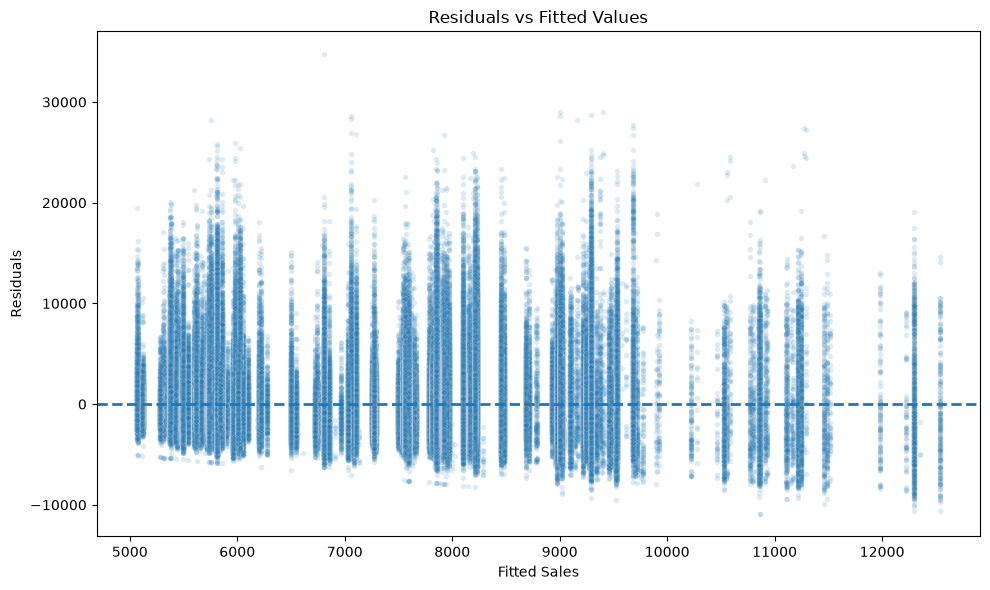

In [99]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=fitted_values,
    y=residuals,
    alpha=0.15,
    s=15
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=2
)

plt.title("Residuals vs Fitted Values")
plt.xlabel("Fitted Sales")
plt.ylabel("Residuals")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

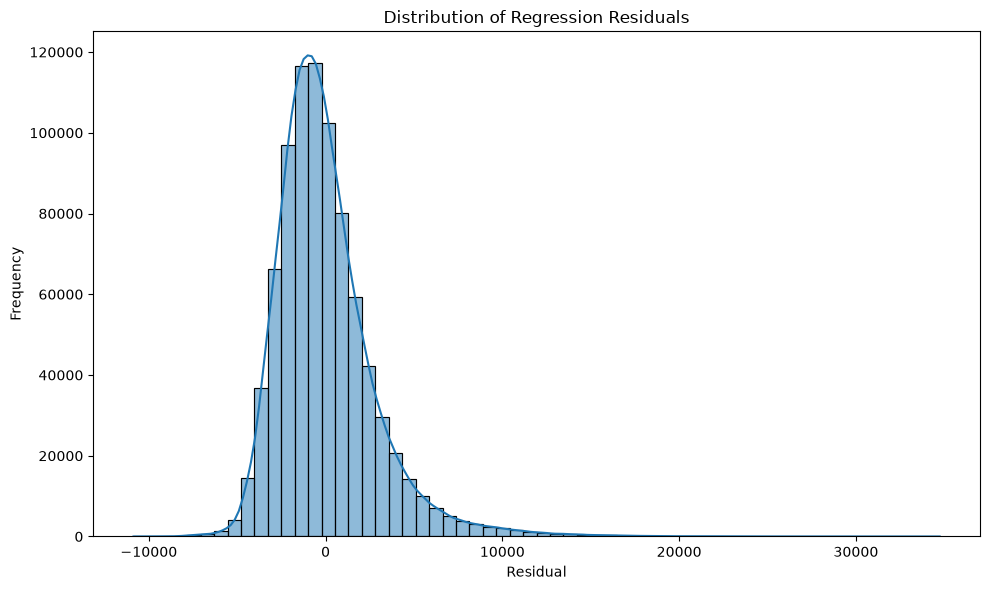

In [100]:
plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=60,
    kde=True
)

plt.title("Distribution of Regression Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

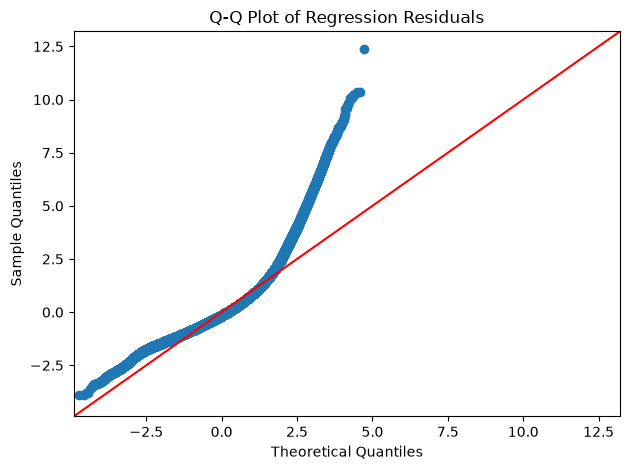

In [101]:
fig = sm.qqplot(
    residuals,
    line="45",
    fit=True
)

plt.title("Q-Q Plot of Regression Residuals")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "residual_qq_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [102]:
from statsmodels.stats.diagnostic import het_breuschpagan

In [103]:
bp_test = het_breuschpagan(
    residuals,
    model_holiday.model.exog
)

bp_labels = [
    "LM Statistic",
    "LM p-value",
    "F Statistic",
    "F p-value"
]

bp_results = pd.Series(
    bp_test,
    index=bp_labels
)

bp_results

LM Statistic    26187.105889
LM p-value          0.000000
F Statistic      1501.368376
F p-value           0.000000
dtype: float64

In [104]:
model_holiday_robust = model_holiday.get_robustcov_results(
    cov_type="HC3"
)

print(model_holiday_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.185
Model:                            OLS   Adj. R-squared:                  0.185
Method:                 Least Squares   F-statistic:                     9614.
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:16:40   Log-Likelihood:            -7.9011e+06
No. Observations:              844392   AIC:                         1.580e+07
Df Residuals:                  844373   BIC:                         1.580e+07
Df Model:                          18                                         
Covariance Type:                  HC3                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                6

In [105]:
regression_df["LogSales"] = np.log1p(
    regression_df["Sales"]
)

model_log = smf.ols(
    formula="""
        LogSales ~ Promo
        + C(DayOfWeek)
        + C(StoreType)
        + Promo:C(StoreType)
        + C(StateHoliday)
        + C(SchoolHoliday)
    """,
    data=regression_df
).fit()

print(model_log.summary())

                            OLS Regression Results                            
Dep. Variable:               LogSales   R-squared:                       0.198
Model:                            OLS   Adj. R-squared:                  0.198
Method:                 Least Squares   F-statistic:                 1.155e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:16:47   Log-Likelihood:            -3.9439e+05
No. Observations:              844392   AIC:                         7.888e+05
Df Residuals:                  844373   BIC:                         7.890e+05
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

In [106]:
log_model_comparison = pd.DataFrame({
    "Model": [
        "Sales scale",
        "Log(1 + Sales) scale"
    ],
    "R_squared": [
        model_holiday.rsquared,
        model_log.rsquared
    ],
    "Adjusted_R_squared": [
        model_holiday.rsquared_adj,
        model_log.rsquared_adj
    ],
    "AIC": [
        model_holiday.aic,
        model_log.aic
    ],
    "BIC": [
        model_holiday.bic,
        model_log.bic
    ]
})

log_model_comparison

,Model,R_squared,Adjusted_R_squared,AIC,BIC
0,Sales scale,0.184954,0.184937,1.580233e+07,1.580255e+07
1,Log(1 + Sales) scale,0.197528,0.197511,7.888148e+05,7.890361e+05


In [107]:
influence = OLSInfluence(model_holiday)

studentized_residuals = influence.resid_studentized_internal
leverage = influence.hat_matrix_diag
cooks_distance = influence.cooks_distance[0]

print("Maximum leverage:", leverage.max())
print("Maximum Cook's distance:", cooks_distance.max())

Maximum leverage: 0.014203448292921307
Maximum Cook's distance: 0.04654168085513236


In [108]:
influence_df = pd.DataFrame({
    "fitted": fitted_values,
    "studentized_residual": studentized_residuals,
    "leverage": leverage,
    "cooks_distance": cooks_distance
})

influence_df.head()

,fitted,studentized_residual,leverage,cooks_distance
0,8216.995328,-1.054069,0.000031,1.809478e-06
1,8478.189715,-0.861445,0.000016,6.301771e-07
2,8478.189715,-0.058587,0.000016,2.914820e-09
3,8216.995328,2.061756,0.000031,6.922922e-06
4,8478.189715,-1.304622,0.000016,1.445364e-06


In [109]:
n = len(regression_df)

cooks_threshold = 4 / n

influential_count = (
    influence_df["cooks_distance"] > cooks_threshold
).sum()

print("Number of observations:", n)
print("Cook's distance screening threshold:", cooks_threshold)
print("Potentially influential observations:", influential_count)

Number of observations: 844392
Cook's distance screening threshold: 4.737136306360079e-06
Potentially influential observations: 33666


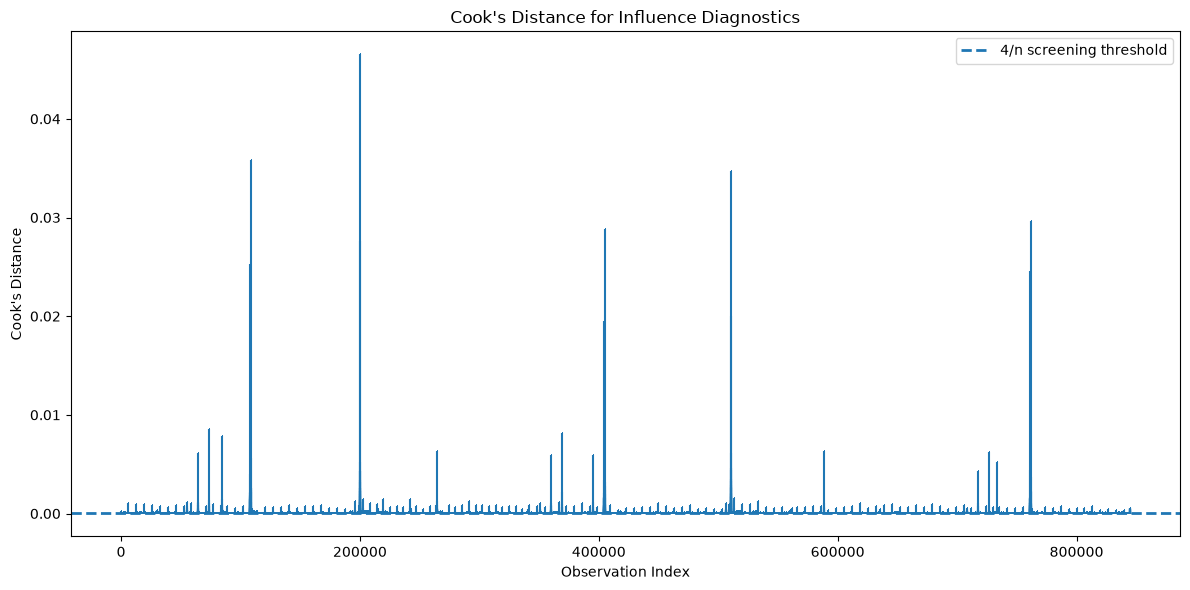

In [110]:
plt.figure(figsize=(12, 6))

plt.stem(
    np.arange(len(cooks_distance)),
    cooks_distance,
    markerfmt=",",
    basefmt=" "
)

plt.axhline(
    cooks_threshold,
    linestyle="--",
    linewidth=2,
    label="4/n screening threshold"
)

plt.title("Cook's Distance for Influence Diagnostics")
plt.xlabel("Observation Index")
plt.ylabel("Cook's Distance")
plt.legend()

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "influence_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [111]:
diagnostic_summary = pd.DataFrame({
    "Diagnostic": [
        "Breusch-Pagan LM statistic",
        "Breusch-Pagan LM p-value",
        "Breusch-Pagan F statistic",
        "Breusch-Pagan F p-value",
        "Maximum leverage",
        "Maximum Cook's distance",
        "Cook's distance threshold",
        "Potentially influential observations"
    ],
    "Value": [
        bp_results["LM Statistic"],
        bp_results["LM p-value"],
        bp_results["F Statistic"],
        bp_results["F p-value"],
        leverage.max(),
        cooks_distance.max(),
        cooks_threshold,
        influential_count
    ]
})

diagnostic_summary

,Diagnostic,Value
0,Breusch-Pagan LM statistic,26187.105889
1,Breusch-Pagan LM p-value,0.000000
2,Breusch-Pagan F statistic,1501.368376
3,Breusch-Pagan F p-value,0.000000
4,Maximum leverage,0.014203
5,Maximum Cook's distance,0.046542
6,Cook's distance threshold,0.000005
7,Potentially influential observations,33666.000000


In [112]:
diagnostic_summary.to_csv(
    OUTPUT_DIR / "regression_diagnostics.csv",
    index=False
)

print("Regression diagnostics saved.")

Regression diagnostics saved.


In [113]:
with open(
    OUTPUT_DIR / "regression_model_summary.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("MAIN EFFECTS MODEL\n")
    f.write(model_main.summary().as_text())

    f.write("\n\nINTERACTION MODEL\n")
    f.write(model_interaction.summary().as_text())

    f.write("\n\nHOLIDAY-ADJUSTED MODEL\n")
    f.write(model_holiday.summary().as_text())

    f.write("\n\nLOG-SALES SENSITIVITY MODEL\n")
    f.write(model_log.summary().as_text())

print("Regression model summaries saved.")

Regression model summaries saved.


In [114]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Main effects",
        "Interaction",
        "Holiday adjusted",
        "Log-sales sensitivity"
    ],
    "R_squared": [
        model_main.rsquared,
        model_interaction.rsquared,
        model_holiday.rsquared,
        model_log.rsquared
    ],
    "Adjusted_R_squared": [
        model_main.rsquared_adj,
        model_interaction.rsquared_adj,
        model_holiday.rsquared_adj,
        model_log.rsquared_adj
    ],
    "AIC": [
        model_main.aic,
        model_interaction.aic,
        model_holiday.aic,
        model_log.aic
    ],
    "BIC": [
        model_main.bic,
        model_interaction.bic,
        model_holiday.bic,
        model_log.bic
    ]
})

final_model_comparison

,Model,R_squared,Adjusted_R_squared,AIC,BIC
0,Main effects,0.181930,0.181920,1.580544e+07,1.580556e+07
1,Interaction,0.183006,0.182993,1.580433e+07,1.580449e+07
2,Holiday adjusted,0.184954,0.184937,1.580233e+07,1.580255e+07
3,Log-sales sensitivity,0.197528,0.197511,7.888148e+05,7.890361e+05


In [115]:
final_model_comparison.to_csv(
    OUTPUT_DIR / "regression_model_comparison.csv",
    index=False
)

print("Final model comparison saved.")

Final model comparison saved.


### Regression Methodology

An ordinary least squares regression model was used to examine the relationship
between daily sales and promotion status while accounting for day of week and
store type. Day of week and store type were treated as categorical factors.

A promotion-by-store-type interaction was included to examine whether the
association between promotion status and sales differed across store types.

State holidays and school holidays were subsequently included to assess
potential holiday-related confounding.

Regression diagnostics included residual-versus-fitted analysis, residual
distribution, Q-Q plot, Breusch-Pagan testing for heteroscedasticity, robust
HC3 standard errors, and influence diagnostics using leverage and Cook's
distance.

Because sales may be strongly right-skewed, a log(1 + sales) sensitivity model
was also estimated to examine whether the overall findings were sensitive to
the scale of the response variable.

# Stage 7: Discriminant Analysis and Classification (M5)

### Classification Target

For the classification task, store-days are divided into two performance
categories using the median daily sales as the threshold.

Store-days with sales greater than or equal to the median are classified as
high-performing, while store-days below the median are classified as
low-performing.

The median is used because it provides a transparent threshold and produces
approximately balanced classes without selecting an arbitrary sales value.

In [116]:
classification_df = analysis_df.copy()

sales_median = classification_df["Sales"].median()

print("Median sales threshold:", sales_median)

Median sales threshold: 6369.0


In [117]:
classification_df["HighPerformance"] = (
    classification_df["Sales"] >= sales_median
).astype(int)

print(
    classification_df["HighPerformance"].value_counts()
)

print("\nClass proportions:")
print(
    classification_df["HighPerformance"]
    .value_counts(normalize=True)
    .sort_index()
)

HighPerformance
1    422230
0    422162
Name: count, dtype: int64

Class proportions:
HighPerformance
0    0.49996
1    0.50004
Name: proportion, dtype: float64


In [118]:
class_distribution = (
    classification_df["HighPerformance"]
    .value_counts()
    .sort_index()
)

class_distribution

HighPerformance
0    422162
1    422230
Name: count, dtype: int64

In [119]:
classification_features = [
    "Promo",
    "DayOfWeek",
    "StoreType",
    "StateHoliday",
    "SchoolHoliday",
    "CompetitionDistance"
]

classification_df[
    classification_features + ["HighPerformance"]
].head()

,Promo,DayOfWeek,StoreType,StateHoliday,SchoolHoliday,CompetitionDistance,HighPerformance
0,1,5,c,0,1,1270.0,0
1,1,5,a,0,1,570.0,0
2,1,5,a,0,1,14130.0,1
3,1,5,c,0,1,620.0,1
4,1,5,a,0,1,29910.0,0


In [120]:
print(
    classification_df[
        classification_features + ["HighPerformance"]
    ].isnull().sum()
)

Promo                     0
DayOfWeek                 0
StoreType                 0
StateHoliday              0
SchoolHoliday             0
CompetitionDistance    2186
HighPerformance           0
dtype: int64


In [121]:
classification_model_df = classification_df[
    classification_features + ["HighPerformance"]
].copy()

classification_model_df["DayOfWeek"] = (
    classification_model_df["DayOfWeek"].astype("category")
)

classification_model_df["StoreType"] = (
    classification_model_df["StoreType"].astype("category")
)

classification_model_df["StateHoliday"] = (
    classification_model_df["StateHoliday"].astype("category")
)

print(classification_model_df.shape)

(844392, 7)


In [122]:
competition_median = (
    classification_model_df["CompetitionDistance"].median()
)

classification_model_df["CompetitionDistance"] = (
    classification_model_df["CompetitionDistance"]
    .fillna(competition_median)
)

print(
    "Remaining missing values:",
    classification_model_df.isnull().sum().sum()
)

Remaining missing values: 0


In [123]:
X = classification_model_df[
    classification_features
]

y = classification_model_df[
    "HighPerformance"
]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (844392, 6)
Target shape: (844392,)


In [124]:
X_encoded = pd.get_dummies(
    X,
    columns=[
        "DayOfWeek",
        "StoreType",
        "StateHoliday"
    ],
    drop_first=True,
    dtype=int
)

print("Encoded feature matrix shape:", X_encoded.shape)
print(X_encoded.head())

Encoded feature matrix shape: (844392, 16)
   Promo  SchoolHoliday  CompetitionDistance  DayOfWeek_2  DayOfWeek_3  \
0      1              1               1270.0            0            0   
1      1              1                570.0            0            0   
2      1              1              14130.0            0            0   
3      1              1                620.0            0            0   
4      1              1              29910.0            0            0   

   DayOfWeek_4  DayOfWeek_5  DayOfWeek_6  DayOfWeek_7  StoreType_b  \
0            0            1            0            0            0   
1            0            1            0            0            0   
2            0            1            0            0            0   
3            0            1            0            0            0   
4            0            1            0            0            0   

   StoreType_c  StoreType_d  StateHoliday_0  StateHoliday_a  StateHoliday_b  \
0           

In [125]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))

Training observations: 675513
Testing observations: 168879

Training class proportions:
HighPerformance
1    0.500041
0    0.499959
Name: proportion, dtype: float64

Testing class proportions:
HighPerformance
1    0.500038
0    0.499962
Name: proportion, dtype: float64


In [126]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [127]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

print("Classification pipeline created.")

Classification pipeline created.


In [128]:
logistic_model.fit(
    X_train,
    y_train
)

print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


In [129]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated.")

Predictions generated.


In [130]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [131]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.6835
Precision: 0.7011
Recall   : 0.6398
F1-score : 0.6690
ROC-AUC  : 0.7133


In [132]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion matrix:")
print(cm)

Confusion matrix:
[[61396 23037]
 [30419 54027]]


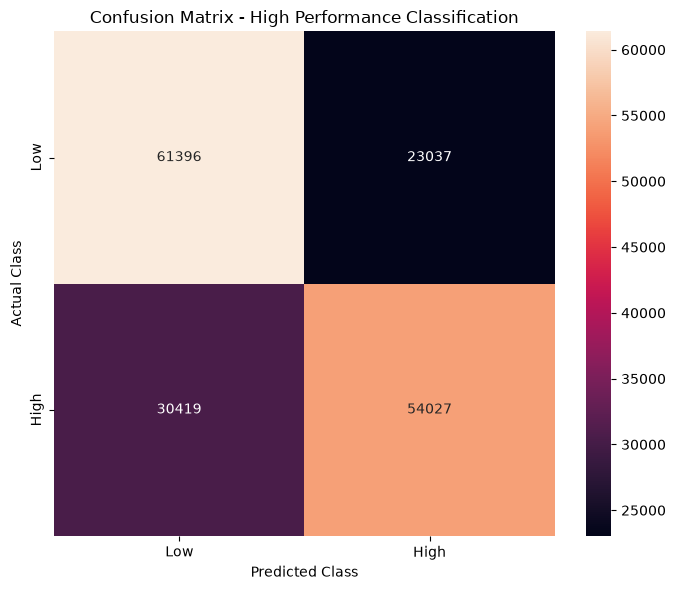

In [133]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Low", "High"],
    yticklabels=["Low", "High"]
)

plt.title("Confusion Matrix - High Performance Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [134]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Low-performing",
            "High-performing"
        ]
    )
)

                 precision    recall  f1-score   support

 Low-performing       0.67      0.73      0.70     84433
High-performing       0.70      0.64      0.67     84446

       accuracy                           0.68    168879
      macro avg       0.68      0.68      0.68    168879
   weighted avg       0.68      0.68      0.68    168879



In [135]:
classification_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

classification_metrics

,Metric,Value
0,Accuracy,0.683466
1,Precision,0.701067
2,Recall,0.639782
3,F1-score,0.669024
4,ROC-AUC,0.713277


In [136]:
classification_metrics.to_csv(
    OUTPUT_DIR / "classification_metrics.csv",
    index=False
)

print("Classification metrics saved.")

Classification metrics saved.


In [137]:
classifier = logistic_model.named_steps["classifier"]

coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": classifier.coef_[0]
})

coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

coefficient_table

,Feature,Coefficient,Absolute_Coefficient
0,Promo,0.814564,0.814564
4,DayOfWeek_3,-0.291783,0.291783
5,DayOfWeek_4,-0.284066,0.284066
3,DayOfWeek_2,-0.209442,0.209442
9,StoreType_b,0.187150,0.187150
6,DayOfWeek_5,-0.163992,0.163992
7,DayOfWeek_6,-0.128616,0.128616
12,StateHoliday_0,0.062100,0.062100
1,SchoolHoliday,0.061489,0.061489
11,StoreType_d,0.034516,0.034516


In [138]:
coefficient_table.to_csv(
    OUTPUT_DIR / "classification_coefficients.csv",
    index=False
)

print("Classification coefficients saved.")

Classification coefficients saved.


In [139]:
targeting_df = X_test.copy()

targeting_df["ActualHighPerformance"] = (
    y_test.values
)

targeting_df["PredictedProbability"] = (
    y_prob
)

targeting_df = targeting_df.sort_values(
    "PredictedProbability",
    ascending=False
).reset_index(drop=True)

targeting_df.head()

,Promo,SchoolHoliday,CompetitionDistance,DayOfWeek_2,DayOfWeek_3,DayOfWeek_4,DayOfWeek_5,DayOfWeek_6,DayOfWeek_7,StoreType_b,StoreType_c,StoreType_d,StateHoliday_0,StateHoliday_a,StateHoliday_b,StateHoliday_c,ActualHighPerformance,PredictedProbability
0,1,1,3640.0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0.946809
1,1,1,1430.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785
2,1,1,1430.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785
3,1,1,1410.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785
4,1,1,1410.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785


In [140]:
targeting_df["CumulativeHighPerformers"] = (
    targeting_df["ActualHighPerformance"]
    .cumsum()
)

targeting_df["Rank"] = (
    np.arange(1, len(targeting_df) + 1)
)

targeting_df["CumulativePopulation"] = (
    targeting_df["Rank"] / len(targeting_df)
)

total_positive_rate = (
    targeting_df["ActualHighPerformance"].mean()
)

targeting_df["CumulativePositiveRate"] = (
    targeting_df["CumulativeHighPerformers"]
    / targeting_df["Rank"]
)

targeting_df["Lift"] = (
    targeting_df["CumulativePositiveRate"]
    / total_positive_rate
)

targeting_df.head()

,Promo,SchoolHoliday,CompetitionDistance,DayOfWeek_2,DayOfWeek_3,DayOfWeek_4,DayOfWeek_5,DayOfWeek_6,DayOfWeek_7,StoreType_b,StoreType_c,StoreType_d,StateHoliday_0,StateHoliday_a,StateHoliday_b,StateHoliday_c,ActualHighPerformance,PredictedProbability,CumulativeHighPerformers,Rank,CumulativePopulation,CumulativePositiveRate,Lift
0,1,1,3640.0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0.946809,0,1,0.000006,0.000000,0.000000
1,1,1,1430.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785,1,2,0.000012,0.500000,0.999923
2,1,1,1430.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785,2,3,0.000018,0.666667,1.333231
3,1,1,1410.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785,3,4,0.000024,0.750000,1.499885
4,1,1,1410.0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0.946785,4,5,0.000030,0.800000,1.599877


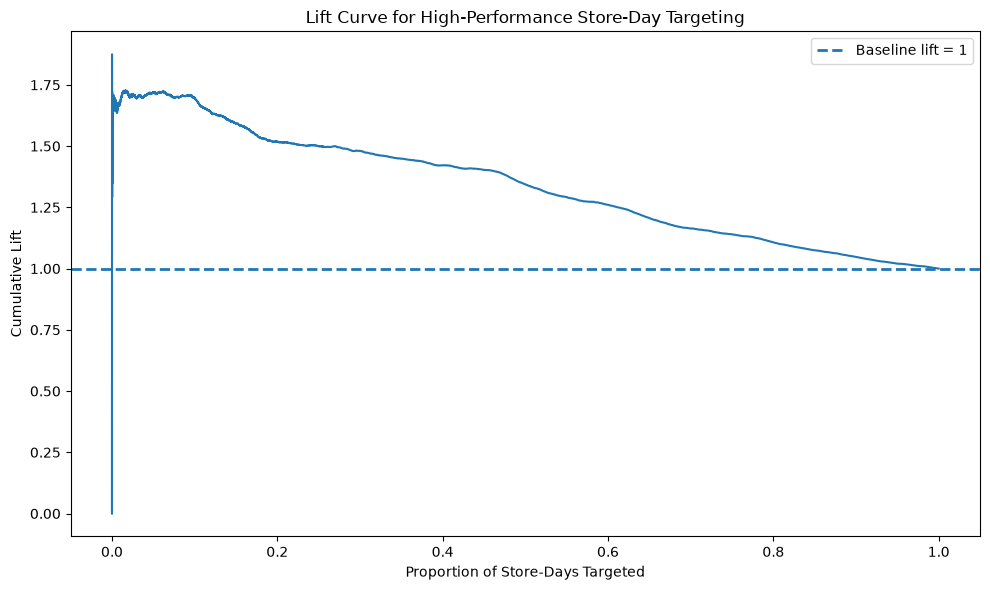

In [141]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=targeting_df,
    x="CumulativePopulation",
    y="Lift"
)

plt.axhline(
    1,
    linestyle="--",
    linewidth=2,
    label="Baseline lift = 1"
)

plt.xlabel("Proportion of Store-Days Targeted")
plt.ylabel("Cumulative Lift")

plt.title("Lift Curve for High-Performance Store-Day Targeting")

plt.legend()

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "lift_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [142]:
targeting_levels = [0.10, 0.20, 0.30, 0.40, 0.50]

lift_results = []

for level in targeting_levels:
    index = max(
        1,
        int(np.ceil(level * len(targeting_df)))
    )

    lift_value = targeting_df.loc[
        index - 1,
        "Lift"
    ]

    lift_results.append({
        "Targeted_Proportion": level,
        "Lift": lift_value
    })

lift_table = pd.DataFrame(lift_results)

lift_table

,Targeted_Proportion,Lift
0,0.1,1.696340
1,0.2,1.517825
2,0.3,1.481017
3,0.4,1.421729
4,0.5,1.343833


In [143]:
targeting_results = []

for level in targeting_levels:
    index = max(
        1,
        int(np.ceil(level * len(targeting_df)))
    )

    selected = targeting_df.iloc[:index]

    precision_at_level = (
        selected["ActualHighPerformance"].mean()
    )

    capture_rate = (
        selected["ActualHighPerformance"].sum()
        /
        targeting_df["ActualHighPerformance"].sum()
    )

    targeting_results.append({
        "Targeted_Proportion": level,
        "Precision": precision_at_level,
        "Capture_Rate": capture_rate,
        "Lift": precision_at_level / total_positive_rate
    })

targeting_table = pd.DataFrame(
    targeting_results
)

targeting_table

,Targeted_Proportion,Precision,Capture_Rate,Lift
0,0.1,0.848235,0.169635,1.696340
1,0.2,0.758971,0.303567,1.517825
2,0.3,0.740565,0.444308,1.481017
3,0.4,0.710919,0.568695,1.421729
4,0.5,0.671968,0.671921,1.343833


In [144]:
lift_table.to_csv(
    OUTPUT_DIR / "lift_results.csv",
    index=False
)

targeting_table.to_csv(
    OUTPUT_DIR / "targeting_results.csv",
    index=False
)

print("Lift and targeting results saved.")

Lift and targeting results saved.


### Classification Methodology

Store-days were classified into high-performing and low-performing categories
using the median daily sales as the threshold. Sales itself was excluded from
the predictor variables to prevent target leakage.

A logistic regression classifier was trained using promotion status, day of
week, store type, holiday indicators and competition distance. The data was
divided into training and testing sets using stratified sampling.

Classification performance was evaluated using accuracy, precision, recall,
F1-score and ROC-AUC. A lift curve was also constructed by ranking test
observations according to their predicted probability of high performance.

The lift analysis evaluates how efficiently a targeted subset of store-days
could identify high-performing observations compared with untargeted selection.

### Interpretation of the Targeting Analysis

The lift analysis describes the predictive usefulness of the classification
model for identifying high-performing store-days.

It does not establish that targeting a store-day with a promotion will cause
high sales. The model predicts performance based on observed characteristics;
therefore, the lift curve should not be interpreted as a causal estimate of
promotion effectiveness.

A targeted promotion strategy would require additional information about
promotion cost, expected incremental sales, profit margin and operational
constraints before assessing commercial value.

In [145]:
targeting_df.to_csv(
    OUTPUT_DIR / "classification_targeting_predictions.csv",
    index=False
)

print("Targeting predictions saved.")

Targeting predictions saved.


In [146]:
print("=" * 60)
print("M5 CLASSIFICATION SUMMARY")
print("=" * 60)

print(f"Median sales threshold: {sales_median:.2f}")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nLift at targeting levels:")
print(lift_table)

M5 CLASSIFICATION SUMMARY
Median sales threshold: 6369.00
Accuracy : 0.6835
Precision: 0.7011
Recall   : 0.6398
F1-score : 0.6690
ROC-AUC  : 0.7133

Lift at targeting levels:
   Targeted_Proportion      Lift
0                  0.1  1.696340
1                  0.2  1.517825
2                  0.3  1.481017
3                  0.4  1.421729
4                  0.5  1.343833


In [147]:
from pathlib import Path

print("OUTPUT FILES CHECK")
print("=" * 50)

required_outputs = [
    "analysis_dataset.csv",
    "bootstrap_results.csv",
    "ttest_results.csv",
    "regression_main_effects.csv",
    "regression_interaction_coefficients.csv",
    "regression_holiday_adjusted.csv",
    "regression_diagnostics.csv",
    "regression_model_comparison.csv",
    "regression_model_summary.txt",
    "classification_metrics.csv",
    "classification_coefficients.csv",
    "lift_results.csv",
    "targeting_results.csv",
    "classification_targeting_predictions.csv"
]

for filename in required_outputs:
    path = OUTPUT_DIR / filename
    status = "✓ FOUND" if path.exists() else "✗ MISSING"
    print(f"{status:10} {filename}")

OUTPUT FILES CHECK
✓ FOUND    analysis_dataset.csv
✓ FOUND    bootstrap_results.csv
✓ FOUND    ttest_results.csv
✓ FOUND    regression_main_effects.csv
✓ FOUND    regression_interaction_coefficients.csv
✓ FOUND    regression_holiday_adjusted.csv
✓ FOUND    regression_diagnostics.csv
✓ FOUND    regression_model_comparison.csv
✓ FOUND    regression_model_summary.txt
✓ FOUND    classification_metrics.csv
✓ FOUND    classification_coefficients.csv
✓ FOUND    lift_results.csv
✓ FOUND    targeting_results.csv
✓ FOUND    classification_targeting_predictions.csv


In [148]:
print("FIGURES CHECK")
print("=" * 50)

required_figures = [
    "sales_by_day.png",
    "sales_by_month.png",
    "promotion_boxplot.png",
    "store_type_distribution.png",
    "bootstrap_distribution.png",
    "regression_diagnostics.png",
    "influence_plot.png",
    "confusion_matrix.png",
    "lift_curve.png"
]

for filename in required_figures:
    path = PROJECT_ROOT / "figures" / filename
    status = "✓ FOUND" if path.exists() else "✗ MISSING"
    print(f"{status:10} {filename}")

FIGURES CHECK
✓ FOUND    sales_by_day.png
✓ FOUND    sales_by_month.png
✓ FOUND    promotion_boxplot.png
✓ FOUND    store_type_distribution.png
✓ FOUND    bootstrap_distribution.png
✗ MISSING  regression_diagnostics.png
✓ FOUND    influence_plot.png
✓ FOUND    confusion_matrix.png
✓ FOUND    lift_curve.png


In [149]:
from pathlib import Path

figures_dir = PROJECT_ROOT / "figures"

print("ALL FIGURES PRESENT:")
print("=" * 50)

for file in sorted(figures_dir.iterdir()):
    if file.is_file():
        print(file.name)

ALL FIGURES PRESENT:
bootstrap_distribution.png
confusion_matrix.png
day_promotion_sales.png
influence_plot.png
lift_curve.png
monthly_sales_trend.png
promotion_boxplot.png
residual_distribution.png
residual_qq_plot.png
residuals_vs_fitted.png
sales_by_day.png
sales_by_month.png
sales_distribution_by_day.png
store_type_distribution.png
store_type_promotion.png


In [150]:
from pathlib import Path

print("OUTPUT FILES CHECK")
print("=" * 50)

required_outputs = [
    "analysis_dataset.csv",
    "bootstrap_results.csv",
    "ttest_results.csv",
    "regression_main_effects.csv",
    "regression_interaction_coefficients.csv",
    "regression_holiday_adjusted.csv",
    "regression_diagnostics.csv",
    "regression_model_comparison.csv",
    "regression_model_summary.txt",
    "classification_metrics.csv",
    "classification_coefficients.csv",
    "lift_results.csv",
    "targeting_results.csv",
    "classification_targeting_predictions.csv"
]

for filename in required_outputs:
    path = OUTPUT_DIR / filename
    status = "✓ FOUND" if path.exists() else "✗ MISSING"
    print(f"{status:10} {filename}")

OUTPUT FILES CHECK
✓ FOUND    analysis_dataset.csv
✓ FOUND    bootstrap_results.csv
✓ FOUND    ttest_results.csv
✓ FOUND    regression_main_effects.csv
✓ FOUND    regression_interaction_coefficients.csv
✓ FOUND    regression_holiday_adjusted.csv
✓ FOUND    regression_diagnostics.csv
✓ FOUND    regression_model_comparison.csv
✓ FOUND    regression_model_summary.txt
✓ FOUND    classification_metrics.csv
✓ FOUND    classification_coefficients.csv
✓ FOUND    lift_results.csv
✓ FOUND    targeting_results.csv
✓ FOUND    classification_targeting_predictions.csv


In [152]:
print("========== M1: EDA ==========")

print("\nPromotion Sales Summary:")
display(pd.read_csv(OUTPUT_DIR / "promotion_sales_summary.csv"))

print("\nStore Type Frequency:")
display(pd.read_csv(OUTPUT_DIR / "store_type_frequency.csv"))

print("\nSales by Day:")
display(pd.read_csv(OUTPUT_DIR / "sales_by_day_summary.csv"))

print("\nSales by Month:")
display(pd.read_csv(OUTPUT_DIR / "sales_by_month_summary.csv"))

========== M1: EDA ==========

Promotion Sales Summary:


,Promo,count,mean,median,std
0,0,467496,5929.407603,5459.0,2629.648385
1,1,376896,8228.281239,7649.0,3175.759157



Store Type Frequency:


,StoreType,Frequency,Percentage
0,a,457077,54.13
1,b,15563,1.84
2,c,112978,13.38
3,d,258774,30.65



Sales by Day:


,DayOfWeek,count,mean,median,std,Day
0,1,137560,8216.073074,7539.0,3691.768876,Monday
1,2,143961,7088.113656,6502.0,3066.237110,Tuesday
2,3,141936,6728.122978,6210.0,2781.775174,Wednesday
3,4,134644,6767.310159,6246.0,2764.548119,Thursday
4,5,138640,7072.677012,6580.0,2764.915744,Friday
5,6,144058,5874.840238,5425.0,2852.730426,Saturday
6,7,3593,8224.723908,6876.0,6235.152960,Sunday



Sales by Month:


,Month,count,mean,median,std,MonthName
0,1,86343,6563.690444,6062.0,2849.588618,January
1,2,80243,6589.165535,6078.0,2870.958982,February
2,3,85980,6976.412026,6385.0,3123.919916,March
3,4,81731,7046.228420,6431.0,3138.850850,April
4,5,80103,7106.453154,6592.0,3008.182746,May
5,6,82576,7000.978190,6365.0,3145.066576,June
6,7,85587,6952.682125,6407.0,3004.087868,July
7,8,54413,6648.984654,6124.0,2901.801310,August
8,9,52330,6546.343035,5999.0,2890.460475,September
9,10,53292,6602.843354,6105.0,2814.725466,October


In [153]:
print("========== M2: BOOTSTRAP ==========")

bootstrap_results = pd.read_csv(
    OUTPUT_DIR / "bootstrap_results.csv"
)

display(bootstrap_results)

========== M2: BOOTSTRAP ==========


,Statistic,Value
0,Ordinary-day mean sales,5929.407603
1,Promotion-day mean sales,8228.281239
2,Observed mean uplift,2298.873636
3,Observed percentage uplift,38.770714
4,Bootstrap standard error,6.454711
5,95% CI lower,2286.638298
6,95% CI upper,2311.561173
7,Percentage uplift CI lower,38.564363
8,Percentage uplift CI upper,38.984690


In [154]:
print("========== M3: SIGNIFICANCE TESTING ==========")

ttest_results = pd.read_csv(
    OUTPUT_DIR / "ttest_results.csv"
)

display(ttest_results)

========== M3: SIGNIFICANCE TESTING ==========


,Statistic,Value
0,Ordinary-day mean,5929.407603
1,Promotion-day mean,8228.281239
2,Mean difference,2298.873636
3,Percentage difference,38.770714
4,Welch t-statistic,356.635724
5,Welch degrees of freedom,729119.029980
6,p-value,0.000000
7,95% CI lower,2286.239688
8,95% CI upper,2311.507583
9,Cohen's d,0.796505


In [155]:
print("========== M4: REGRESSION ==========")

print("\nModel Comparison:")
display(
    pd.read_csv(
        OUTPUT_DIR / "regression_model_comparison.csv"
    )
)

print("\nRegression Diagnostics:")
display(
    pd.read_csv(
        OUTPUT_DIR / "regression_diagnostics.csv"
    )
)

========== M4: REGRESSION ==========

Model Comparison:


,Model,R_squared,Adjusted_R_squared,AIC,BIC
0,Main effects,0.181930,0.181920,1.580544e+07,1.580556e+07
1,Interaction,0.183006,0.182993,1.580433e+07,1.580449e+07
2,Holiday adjusted,0.184954,0.184937,1.580233e+07,1.580255e+07
3,Log-sales sensitivity,0.197528,0.197511,7.888148e+05,7.890361e+05



Regression Diagnostics:


,Diagnostic,Value
0,Breusch-Pagan LM statistic,26187.105889
1,Breusch-Pagan LM p-value,0.000000
2,Breusch-Pagan F statistic,1501.368376
3,Breusch-Pagan F p-value,0.000000
4,Maximum leverage,0.014203
5,Maximum Cook's distance,0.046542
6,Cook's distance threshold,0.000005
7,Potentially influential observations,33666.000000


In [156]:
print("========== M5: CLASSIFICATION ==========")

print("\nClassification Metrics:")
display(
    pd.read_csv(
        OUTPUT_DIR / "classification_metrics.csv"
    )
)

print("\nLift Results:")
display(
    pd.read_csv(
        OUTPUT_DIR / "lift_results.csv"
    )
)

========== M5: CLASSIFICATION ==========

Classification Metrics:


,Metric,Value
0,Accuracy,0.683466
1,Precision,0.701067
2,Recall,0.639782
3,F1-score,0.669024
4,ROC-AUC,0.713277



Lift Results:


,Targeted_Proportion,Lift
0,0.1,1.696340
1,0.2,1.517825
2,0.3,1.481017
3,0.4,1.421729
4,0.5,1.343833
